# TP N.º 3 — Exploración y Análisis de Datos

**Materia:** Prácticas Profesionalizantes  
**Carrera:** Tecnicatura Superior en Ciencia de Datos e IA  
**Estudiante:** Sandra L. Domínguez  
**Punto de partida:** `dataset_adjudicaciones_limpio_preparado.csv`  

---

### Acceso a los Datasets

* **Dataset de partida (CSV Limpio e Intermedio):** [Ver / Descargar dataset_adjudicaciones_limpio_2016_2019.csv](https://drive.google.com/file/d/1qES60UPlPJ8JWezp1dUJMyoF9dfzoqMT/view?usp=drive_link)
* **Dataset optimizado (CSV Preparado para TP3 y TP4):** [Ver / Descargar dataset_adjudicaciones_limpio_preparado.csv](https://drive.google.com/file/d/13K4dUcsKggBr2dJ0IELzqV2E40NNUS7a/view?usp=drive_link)



> **Nota aclaratoria:** Para esta fase de análisis exploratorio y posterior armado del Dashboard en el TP N.º 4, se utiliza la versión optimizada (`dataset_adjudicaciones_limpio_preparado.csv`). Esta versión mantiene los 26.500 registros y la integridad de los datos originales, incorporando el casteo explícito de los campos de fecha (`datetime64`) e identificadores (`string`), lo que resuelve las inconsistencias de formato en los filtros temporales y gráficos.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# 1. Montar Google Drive
drive.mount('/content/drive')

# 2. Cargar el dataset optimizado exportado desde el TP2
path = '/content/drive/MyDrive/ColabNotebooks/AnalisisYExploraciónDeDatos/dataset_adjudicaciones_2016_2019_limpio_preparado.csv'

df = pd.read_csv(
    path,
    parse_dates=['Fecha_de_perfeccionamiento_OC', 'Fecha_de_Adjudicacion'],
    dtype={'Nro_SAF': str, 'Nro_UOC': str, 'CUIT': str},
)

# 3. Asegurar formato de enteros puros (sin decimales .0) para años y meses
df['Anio_OC'] = df['Anio_OC'].astype('Int64')
df['Mes_OC'] = df['Mes_OC'].astype('Int64')
df['Anio_Adjudicacion'] = df['Anio_Adjudicacion'].astype('Int64')

print(
    f'Dataset cargado exitosamente. Filas: {df.shape[0]}, Columnas:'
    f' {df.shape[1]}'
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset cargado exitosamente. Filas: 26500, Columnas: 25


## Punto 1: Preguntas de análisis
1. Evolución temporal del gasto y transacciones (Análisis Temporal):<br> ¿Cómo varió el volumen total de montos adjudicados (en ARS) y la cantidad de contrataciones perfeccionadas año a año durante el período 2016–2019?
2. Comparación por Tipo de Procedimiento (Comparación de Grupos):<br> ¿Qué proporción del total de adjudicaciones se realiza mediante Licitación Pública frente a Contratación Directa, y cómo difieren en su monto promedio por operación?   
3. Distribución de montos y dispersión (Análisis de Variable Numérica):<br> ¿Cuál es la distribución general de los montos de adjudicación y qué impacto generan los valores atípicos (outliers) sobre la media respecto a la mediana?   
4. Concentración de proveedores (Métricas e Indicadores):<br> ¿Quiénes son los 10 principales proveedores con mayor facturación acumulada y qué porcentaje del presupuesto total concentran?   
5. Distribución por rubros y sectores (Participación por Categoría):<br> ¿Cuáles son los 5 rubros comerciales con mayor presupuesto asignado por el Estado Nacional durante el quinquenio?   
6. Concentración por organismos y detección de patrones (Anomalías y Comportamiento):<br> ¿Qué Servicios Administrativos Financieros (SAF / Ministerios) concentran el mayor gasto y existen patrones o estacionalidades en los meses de cierre de año (noviembre/diciembre)?

## 2. Plan de análisis

| Pregunta | Variables necesarias | Métrica / análisis | Qué se espera observar |
| :--- | :--- | :--- | :--- |
| **1. Evolución temporal** | `Anio_OC`, `Monto`, `Moneda`, `Es_Monto_Valido` | Suma total de montos y conteo de OC por año <br> (filtrado `Moneda == 'Peso Argentino'`). | Tendencia del gasto público anual y variaciones <br>  en la cantidad de trámites. |
| **2. Tipos de procedimiento** | `Tipo_de_Procedimiento`, `Monto`, `Moneda` | Porcentaje de participación (%) sobre el total y <br> monto promedio (media) por categoría. | Dominancia de contrataciones directas en cantidad vs. <br>  licitaciones en volumen de dinero. |
| **3. Distribución de montos** | `Monto`, `Moneda`, `Es_Monto_Valido` | Media, mediana, desviación estándar, percentiles <br> (p25, p50, p75, p99) y máx/mín. | Asimetría positiva pronunciada causada por contrataciones <br>  multimillonarias. |
| **4. Concentración de proveedores** | `Descripcion_Proveedor`, `CUIT`, `Monto`, `Moneda` | Suma acumulada por CUIT/Proveedor y porcentaje <br> del total (Monto\_Prov / Monto\_Total$). | Nivel de concentración del mercado público en pocos <br>  proveedores clave. |
| **5. Análisis por rubros** | `Rubros`, `Monto`, `Moneda` | Total acumulado y ranking Top 5 de rubros comerciales. | Sectores económicos con mayor demanda presupuestaria <br>  (salud, obras, servicios). |
| **6. Organismos y estacionalidad** | `Descripcion_SAF`, `Mes_OC`, `Monto`, `Moneda` | Agrupación por SAF y distribución mensual de compras. | Concentración del gasto en ministerios clave y pico <br>  de ejecuciones a fin de año. |

In [13]:
# --- PUNTO 3: EXPLORACIÓN Y ANÁLISIS ---

# 1. Filtrado para análisis financiero en Pesos Argentinos (ARS) y montos válidos (>0)
df_ars = df[(df['Moneda'] == 'Peso Argentino') & (df['Es_Monto_Valido'] == True)].copy()

# ==============================================================================
# PREGUNTA 1: EVOLUCIÓN TEMPORAL DEL GASTO Y TRANSACCIONES (2016-2019)
# ==============================================================================
q1_res = df_ars[df_ars['Anio_OC'].between(2016, 2019)].groupby('Anio_OC').agg(
    Monto_Total_ARS=('Monto', 'sum'),
    Cantidad_OC=('Documento_Contractual', 'count'),
    Monto_Promedio_ARS=('Monto', 'mean')
).reset_index()

# Formatear números para lectura ejecutiva
q1_res_tabla = q1_res.copy()
q1_res_tabla['Anio_OC'] = q1_res_tabla['Anio_OC'].astype(int)
q1_res_tabla['Monto_Total_ARS'] = q1_res_tabla['Monto_Total_ARS'].map('${:,.2f}'.format)
q1_res_tabla['Monto_Promedio_ARS'] = q1_res_tabla['Monto_Promedio_ARS'].map('${:,.2f}'.format)

print("=== PREGUNTA 1: EVOLUCIÓN TEMPORAL DE ADJUDICACIONES ===")
display(q1_res_tabla)



=== PREGUNTA 1: EVOLUCIÓN TEMPORAL DE ADJUDICACIONES ===


,Anio_OC,Monto_Total_ARS,Cantidad_OC,Monto_Promedio_ARS
0,2016,"$608,297,735.66",139,"$4,376,242.70"
1,2017,"$13,697,578,597.07",3824,"$3,582,002.77"
2,2018,"$28,771,603,145.03",11293,"$2,547,737.82"
3,2019,"$19,434,558,588.95",10263,"$1,893,652.79"


In [14]:
# ==============================================================================
# PREGUNTA 2: COMPARACIÓN POR TIPO DE PROCEDIMIENTO
# ==============================================================================
q2_res = df_ars.groupby('Tipo_de_Procedimiento', observed=False).agg(
    Cantidad_OC=('Documento_Contractual', 'count'),
    Monto_Total_ARS=('Monto', 'sum'),
    Monto_Promedio_ARS=('Monto', 'mean')
).reset_index()

# Métricas porcentuales
total_monto_ars = df_ars['Monto'].sum()
total_oc_ars = len(df_ars)

q2_res['Porcentaje_Cantidad'] = (q2_res['Cantidad_OC'] / total_oc_ars) * 100
q2_res['Porcentaje_Monto'] = (q2_res['Monto_Total_ARS'] / total_monto_ars) * 100

# Ordenar por monto total descendente
q2_res = q2_res.sort_values(by='Monto_Total_ARS', ascending=False)

q2_res_tabla = q2_res.copy()
q2_res_tabla['Monto_Total_ARS'] = q2_res_tabla['Monto_Total_ARS'].map('${:,.2f}'.format)
q2_res_tabla['Monto_Promedio_ARS'] = q2_res_tabla['Monto_Promedio_ARS'].map('${:,.2f}'.format)
q2_res_tabla['Porcentaje_Cantidad'] = q2_res_tabla['Porcentaje_Cantidad'].map('{:.2f}%'.format)
q2_res_tabla['Porcentaje_Monto'] = q2_res_tabla['Porcentaje_Monto'].map('{:.2f}%'.format)

print("\n=== PREGUNTA 2: COMPARACIÓN POR TIPO DE PROCEDIMIENTO ===")
display(q2_res_tabla)


=== PREGUNTA 2: COMPARACIÓN POR TIPO DE PROCEDIMIENTO ===


,Tipo_de_Procedimiento,Cantidad_OC,Monto_Total_ARS,Monto_Promedio_ARS,Porcentaje_Cantidad,Porcentaje_Monto
5,Licitacion Pública,4181,"$29,557,515,734.67","$7,069,484.75",16.38%,47.28%
3,Contratación Directa,14413,"$26,809,284,492.22","$1,860,076.63",56.47%,42.88%
4,Licitacion Privada,6578,"$4,773,438,081.36","$725,667.08",25.77%,7.63%
2,Concurso Público,188,"$1,166,811,094.99","$6,206,441.99",0.74%,1.87%
1,Concurso Privado,133,"$185,207,525.09","$1,392,537.78",0.52%,0.30%
0,Compulsa de Precios,2,"$19,550,833.00","$9,775,416.50",0.01%,0.03%
6,Subasta Pública,30,"$9,476,650.00","$315,888.33",0.12%,0.02%


In [15]:
# ==============================================================================
# PREGUNTA 3: DISTRIBUCIÓN DE MONTOS Y ANÁLISIS DE OUTLIERS
# ==============================================================================
stats_monto = {
    'Métrica': [
        'Cantidad de Registros (N)',
        'Monto Mínimo',
        'Percentil 25 (Q1)',
        'Mediana (Percentil 50 / Q2)',
        'Media (Promedio)',
        'Percentil 75 (Q3)',
        'Percentil 99',
        'Monto Máximo',
        'Desviación Estándar (Std)',
        'Rango Intercuartílico (IQR)'
    ],
    'Valor_ARS': [
        len(df_ars['Monto']),
        df_ars['Monto'].min(),
        df_ars['Monto'].quantile(0.25),
        df_ars['Monto'].median(),
        df_ars['Monto'].mean(),
        df_ars['Monto'].quantile(0.75),
        df_ars['Monto'].quantile(0.99),
        df_ars['Monto'].max(),
        df_ars['Monto'].std(),
        df_ars['Monto'].quantile(0.75) - df_ars['Monto'].quantile(0.25)
    ]
}

df_q3 = pd.DataFrame(stats_monto)

print("=== PREGUNTA 3: ESTADÍSTICAS DESCRIPTIVAS DE MONTOS (ARS) ===")
q3_tabla = df_q3.copy()
q3_tabla['Valor_ARS'] = q3_tabla.apply(
    lambda r: f"{int(r['Valor_ARS']):,}" if r['Métrica'] == 'Cantidad de Registros (N)' else f"${r['Valor_ARS']:,.2f}",
    axis=1
)
display(q3_tabla)



=== PREGUNTA 3: ESTADÍSTICAS DESCRIPTIVAS DE MONTOS (ARS) ===


,Métrica,Valor_ARS
0,Cantidad de Registros (N),"25,525"
1,Monto Mínimo,$0.03
2,Percentil 25 (Q1),"$35,307.10"
3,Mediana (Percentil 50 / Q2),"$146,318.00"
4,Media (Promedio),"$2,449,413.69"
5,Percentil 75 (Q3),"$713,800.00"
6,Percentil 99,"$40,702,816.00"
7,Monto Máximo,"$2,552,449,000.00"
8,Desviación Estándar (Std),"$22,868,186.54"
9,Rango Intercuartílico (IQR),"$678,492.90"


In [16]:
# ==============================================================================
# PREGUNTA 4: CONCENTRACIÓN DE PROVEEDORES (TOP 10 CONSOLIDADO POR CUIT)
# ==============================================================================
df_ars['CUIT_Limpio'] = df_ars['CUIT'].str.strip().str.replace(' ', '')
df_ars['Proveedor_Limpio'] = df_ars['Descripcion_Proveedor'].str.strip().str.rstrip('.')

monto_total_ars = df_ars['Monto'].sum()

q4_prov = df_ars.groupby('CUIT_Limpio').agg(
    Proveedor=('Proveedor_Limpio', 'first'),
    Monto_Total_ARS=('Monto', 'sum'),
    Cantidad_Adjudicaciones=('Documento_Contractual', 'count')
).reset_index()

q4_prov['Porcentaje_Presupuesto'] = (q4_prov['Monto_Total_ARS'] / monto_total_ars) * 100
top10_prov = q4_prov.sort_values(by='Monto_Total_ARS', ascending=False).head(10)

print("\n=== PREGUNTA 4: TOP 10 PROVEEDORES CONSOLIDADOS POR CUIT ===")
q4_tabla = top10_prov.copy()
q4_tabla['Monto_Total_ARS'] = q4_tabla['Monto_Total_ARS'].map('${:,.2f}'.format)
q4_tabla['Porcentaje_Presupuesto'] = q4_tabla['Porcentaje_Presupuesto'].map('{:.2f}%'.format)
display(q4_tabla)


=== PREGUNTA 4: TOP 10 PROVEEDORES CONSOLIDADOS POR CUIT ===


,CUIT_Limpio,Proveedor,Monto_Total_ARS,Cantidad_Adjudicaciones,Porcentaje_Presupuesto
3740,30-70857483-6,CORREO OFICIAL DE LA REPÚBLICA ARGENTINA S.A,"$3,888,287,116.22",52,6.22%
2978,30-678221976-6,FÁBRICA ARGENTINA DE AVIONES BRIG. SAN MARTÍN S.A,"$1,420,658,955.51",4,2.27%
2137,30-54668997-9,YPF SA,"$1,300,206,512.40",84,2.08%
2983,30-67856116-5,NACION SEGUROS S.A,"$1,079,771,473.14",327,1.73%
3125,30-68825409-0,PROVINCIA ART S.A,"$976,846,818.67",13,1.56%
2977,30-67822197-6,FÁBRICA ARGENTINA DE AVIONES BRIG. SAN MARTÍN S.A,"$942,778,444.00",4,1.51%
3006,30-679702307-7,SURELY SA,"$903,119,500.00",2,1.44%
3220,30-69605181-6,LA MANTOVANA DE SERVICIOS GENERALES S.A,"$884,728,475.15",28,1.42%
5314,30-716127237-7,OYMYAKON S.A. - FYN S.A. UNION TRANSITORIA,"$749,820,419.54",1,1.20%
2139,30-54669396-8,DIRECCIÓN GENERAL DE FABRICACIONES MILITARES,"$705,670,023.67",15,1.13%


In [17]:
# ==============================================================================
# PREGUNTA 5: DISTRIBUCIÓN POR RUBROS COMERCIALES (TOP 5)
# ==============================================================================
q5_rubros = df_ars.groupby('Rubros').agg(
    Monto_Total_ARS=('Monto', 'sum'),
    Cantidad_Adjudicaciones=('Documento_Contractual', 'count')
).reset_index()

monto_total_ars = df_ars['Monto'].sum()
q5_rubros['Porcentaje_Presupuesto'] = (q5_rubros['Monto_Total_ARS'] / monto_total_ars) * 100
top5_rubros = q5_rubros.sort_values(by='Monto_Total_ARS', ascending=False).head(5)

print("=== PREGUNTA 5: TOP 5 RUBROS CON MAYOR PRESUPUESTO ===")
q5_tabla = top5_rubros.copy()
q5_tabla['Monto_Total_ARS'] = q5_tabla['Monto_Total_ARS'].map('${:,.2f}'.format)
q5_tabla['Porcentaje_Presupuesto'] = q5_tabla['Porcentaje_Presupuesto'].map('{:.2f}%'.format)
display(q5_tabla)



=== PREGUNTA 5: TOP 5 RUBROS CON MAYOR PRESUPUESTO ===


,Rubros,Monto_Total_ARS,Cantidad_Adjudicaciones,Porcentaje_Presupuesto
1616,SERV. PROFESIONAL Y COMERCIAL,"$14,938,790,604.40",2747,23.89%
18,ALIMENTOS,"$7,442,227,655.42",1463,11.90%
1554,MANT. REPARACION Y LIMPIEZA,"$6,184,333,961.00",2086,9.89%
1594,PROD. MEDICO/FARMACEUTICOS/LAB,"$3,909,592,041.72",340,6.25%
56,ALQUILER,"$2,590,693,925.46",417,4.14%


In [18]:
# ==============================================================================
# PREGUNTA 6A: TOP 5 SERVICIOS ADMINISTRATIVOS FINANCIEROS (SAF / MINISTERIOS)
# ==============================================================================
q6_saf = df_ars.groupby('Descripcion_SAF').agg(
    Monto_Total_ARS=('Monto', 'sum'),
    Cantidad_Adjudicaciones=('Documento_Contractual', 'count')
).reset_index()

q6_saf['Porcentaje_Presupuesto'] = (q6_saf['Monto_Total_ARS'] / monto_total_ars) * 100
top5_saf = q6_saf.sort_values(by='Monto_Total_ARS', ascending=False).head(5)

print("\n=== PREGUNTA 6A: TOP 5 ORGANISMOS COMPRADORES (SAF) ===")
q6a_tabla = top5_saf.copy()
q6a_tabla['Monto_Total_ARS'] = q6a_tabla['Monto_Total_ARS'].map('${:,.2f}'.format)
q6a_tabla['Porcentaje_Presupuesto'] = q6a_tabla['Porcentaje_Presupuesto'].map('{:.2f}%'.format)
display(q6a_tabla)




=== PREGUNTA 6A: TOP 5 ORGANISMOS COMPRADORES (SAF) ===


,Descripcion_SAF,Monto_Total_ARS,Cantidad_Adjudicaciones,Porcentaje_Presupuesto
28,311 - Ministerio de Salud y Desarrollo Social,"$6,092,749,074.85",790,9.75%
26,310 - Secretaría de Gobierno de Salud,"$5,119,619,918.54",248,8.19%
35,325 - Ministerio del Interior; Obras Públicas ...,"$4,487,233,505.69",263,7.18%
74,381 - Estado Mayor General de La Fuerza Aérea,"$4,054,122,676.81",2839,6.48%
51,343 - Ministerio de Seguridad,"$3,231,564,682.96",280,5.17%


In [19]:
# ==============================================================================
# PREGUNTA 6B: ANÁLISIS DE ESTACIONALIDAD MENSUAL (2016-2019)
# ==============================================================================
q6_mes = df_ars[df_ars['Anio_OC'].between(2016, 2019)].groupby('Mes_OC').agg(
    Monto_Total_ARS=('Monto', 'sum'),
    Cantidad_Adjudicaciones=('Documento_Contractual', 'count')
).reset_index()

q6_mes['Porcentaje_Monto'] = (q6_mes['Monto_Total_ARS'] / monto_total_ars) * 100
q6_mes['Mes_OC'] = q6_mes['Mes_OC'].astype(int)

print("\n=== PREGUNTA 6B: ESTACIONALIDAD Y PATRONES POR MES ===")
q6b_tabla = q6_mes.sort_values(by='Mes_OC').copy()
q6b_tabla['Monto_Total_ARS'] = q6b_tabla['Monto_Total_ARS'].map('${:,.2f}'.format)
q6b_tabla['Porcentaje_Monto'] = q6b_tabla['Porcentaje_Monto'].map('{:.2f}%'.format)
display(q6b_tabla)


=== PREGUNTA 6B: ESTACIONALIDAD Y PATRONES POR MES ===


,Mes_OC,Monto_Total_ARS,Cantidad_Adjudicaciones,Porcentaje_Monto
0,1,"$3,246,062,922.17",1205,5.19%
1,2,"$3,536,318,805.70",1268,5.66%
2,3,"$4,569,397,661.41",1594,7.31%
3,4,"$2,928,292,742.99",1248,4.68%
4,5,"$4,477,110,949.61",2037,7.16%
5,6,"$7,140,505,997.00",2084,11.42%
6,7,"$6,596,357,098.07",2257,10.55%
7,8,"$4,340,465,211.84",2211,6.94%
8,9,"$5,584,264,454.59",2414,8.93%
9,10,"$4,752,081,972.85",2519,7.60%


### 5. Resultados e interpretación

#### Pregunta 1: Evolución temporal
* **Análisis / métrica:** Suma total de montos en ARS y cantidad de órdenes de compra por año (`Anio_OC`).
* **Resultado:** Pico de gasto en 2018 (28.771M ARS y 11.293 OC) frente a 2016 (608M ARS y 139 OC).
* **Interpretación:** Refleja la paulatina digitalización de procesos en el portal COMPR.AR y una posterior estabilización con compras de menor monto promedio unitario.

#### Pregunta 2: Tipos de procedimiento
* **Análisis / métrica:** Porcentaje de participación en cantidad de trámites y en monto financiero total (ARS).
* **Resultado:** Contratación Directa representa el 56,47% en trámites (42,88% del dinero). Licitación Pública representa el 16,38% en trámites (47,28% del dinero).
* **Interpretación:** La Contratación Directa resuelve el volumen operativo diario, mientras que la Licitación Pública canaliza los proyectos de mayor volumen presupuestario.

#### Pregunta 3: Distribución de montos
* **Análisis / métrica:** Mediana, Media, Rango Intercuartílico (IQR), Percentil 99 y Monto Máximo.
* **Resultado:** Mediana de 146.318,00 ARS frente a una Media de 2.449.413,69 ARS (Monto Máximo de 2.552M).
* **Interpretación:** Asimetría positiva severa. La media está distorsionada por contrataciones atípicas multimillonarias (obras/energía). La mediana refleja el valor representativo.

#### Pregunta 4: Concentración de proveedores
* **Análisis / métrica:** Agrupación por CUIT consolidado y porcentaje sobre el presupuesto total en ARS.
* **Resultado:** El Top 10 de proveedores acumula 12.851M (20,56% del presupuesto). Lidera Correo Oficial (3.888M / 6,22%).
* **Interpretación:** Fuerte concentración de las contrataciones públicas en empresas estatales o de participación estatal mayoritaria.

#### Pregunta 5: Distribución por rubros
* **Análisis / métrica:** Ranking de rubros comerciales por suma acumulada de gasto en ARS.
* **Resultado:** Top 1: Servicios Profesionales (14.938M / 23,89%). Top 2: Alimentos (7.442M / 11,90%).
* **Interpretación:** Más de la mitad del presupuesto (56%) se destina a servicios profesionales, provisión de alimentos, mantenimiento y salud.

#### Pregunta 6: Organismos y estacionalidad
* **Análisis / métrica:** Agrupación por Servicio Administrativo Financiero (SAF) y distribución mensual de compras (`Mes_OC`).
* **Resultado:** Salud y Desarrollo Social representan el 17,94% del gasto. Noviembre y Diciembre concentran el 24,54% del total.
* **Interpretación:** Muestra la aceleración de ejecuciones contractuales a fin de año para completar la ejecución de los créditos presupuestarios.

### 3.1 Visualización de Resultados Clave
A continuación, se presentan los gráficos explicativos que sintetizan los hallazgos del análisis exploratorio (evolución anual, distribución por procedimiento, estacionalidad mensual y top de rubros).

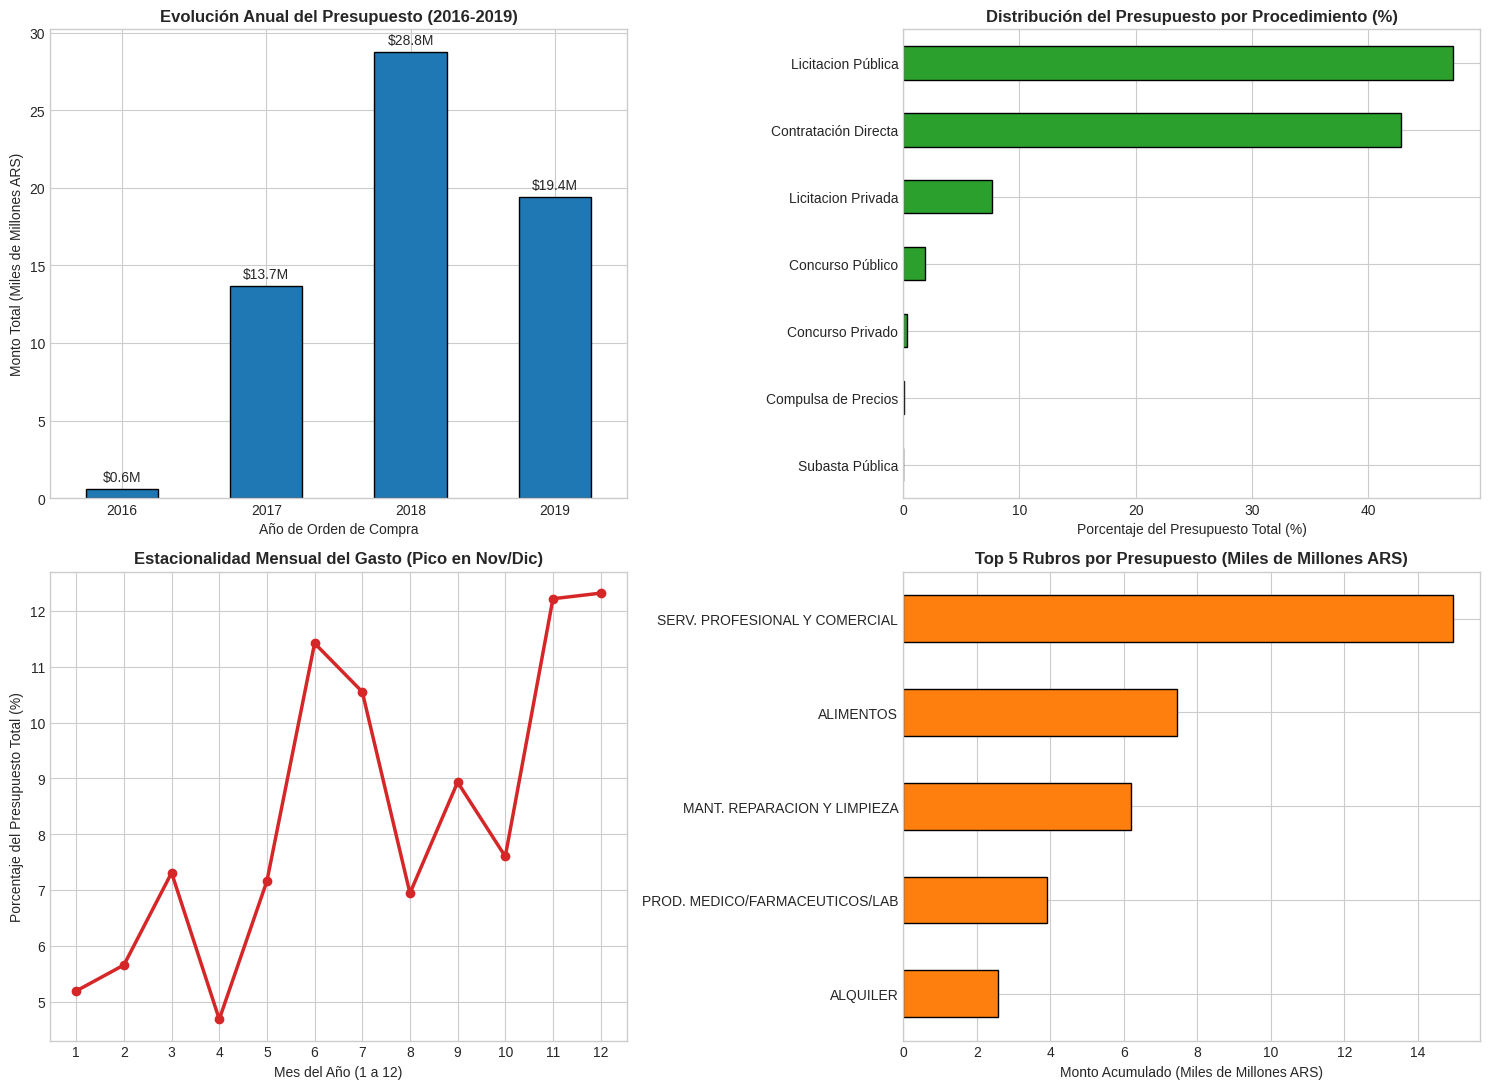

In [22]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configuración de estilo visual
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Gráfico de Evolución Anual (Pregunta 1)
q1 = (
    df_ars[df_ars['Anio_OC'].between(2016, 2019)]
    .groupby('Anio_OC')['Monto']
    .sum()
    / 1e9
)
ax1 = q1.plot(kind='bar', ax=axes[0, 0], color='#1f77b4', edgecolor='black')
axes[0, 0].set_title(
    'Evolución Anual del Presupuesto (2016-2019)',
    fontsize=12,
    fontweight='bold',
)
axes[0, 0].set_ylabel('Monto Total (Miles de Millones ARS)')
axes[0, 0].set_xlabel('Año de Orden de Compra')
axes[0, 0].tick_params(axis='x', rotation=0)

# Agregar etiquetas de valor sobre las barras
for p in ax1.patches:
  ax1.annotate(
      f'${p.get_height():,.1f}M',
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha='center',
      va='bottom',
      xytext=(0, 3),
      textcoords='offset points',
  )

# 2. Gráfico por Tipo de Procedimiento (Pregunta 2)
q2 = (
    df_ars.groupby('Tipo_de_Procedimiento', observed=False)['Monto'].sum()
    / df_ars['Monto'].sum()
    * 100
)
q2_top = q2.sort_values(ascending=True)
q2_top.plot(kind='barh', ax=axes[0, 1], color='#2ca02c', edgecolor='black')
axes[0, 1].set_title(
    'Distribución del Presupuesto por Procedimiento (%)',
    fontsize=12,
    fontweight='bold',
)
axes[0, 1].set_xlabel('Porcentaje del Presupuesto Total (%)')
axes[0, 1].set_ylabel('')

# 3. Gráfico de Estacionalidad Mensual (Pregunta 6B - Efecto Diciembre)
q6 = (
    df_ars[df_ars['Anio_OC'].between(2016, 2019)]
    .groupby('Mes_OC')['Monto']
    .sum()
    / df_ars['Monto'].sum()
    * 100
)
q6.plot(kind='line', marker='o', color='#d62728', linewidth=2.5, ax=axes[1, 0])
axes[1, 0].set_title(
    'Estacionalidad Mensual del Gasto (Pico en Nov/Dic)',
    fontsize=12,
    fontweight='bold',
)
axes[1, 0].set_ylabel('Porcentaje del Presupuesto Total (%)')
axes[1, 0].set_xlabel('Mes del Año (1 a 12)')
axes[1, 0].set_xticks(range(1, 13))

# 4. Top 5 Rubros Comerciales (Pregunta 5)
q5 = (
    df_ars.groupby('Rubros')['Monto'].sum().sort_values(ascending=False).head(5)
    / 1e9
)
q5.sort_values(ascending=True).plot(
    kind='barh', ax=axes[1, 1], color='#ff7f0e', edgecolor='black'
)
axes[1, 1].set_title(
    'Top 5 Rubros por Presupuesto (Miles de Millones ARS)',
    fontsize=12,
    fontweight='bold',
)
axes[1, 1].set_xlabel('Monto Acumulado (Miles de Millones ARS)')
axes[1, 1].set_ylabel('')

plt.tight_layout()
plt.show()

### 5. Resultados e interpretación

| Pregunta | Análisis / métrica utilizada | Resultado | Interpretación |
| :--- | :--- | :--- | :--- |
| **1. Evolución temporal** | Suma de montos y conteo<br>de OC por `Anio_OC` (ARS). | Pico en 2018 (28.771M ARS y 11.293 OC)<br>vs 2016 (608M ARS y 139 OC). | Crecimiento inicial por digitalización<br>en COMPR.AR y estabilización posterior. |
| **2. Tipos de procedimiento** | % de participación en trámites<br>y en monto financiero (ARS). | Directa: 56.47% trámites (42.88% del gasto).<br>Licitación: 16.38% trámites (47.28% del gasto). | Directa resuelve la operatividad diaria;<br>Licitación canaliza grandes inversiones. |
| **3. Distribución de montos** | Mediana, Media, IQR,<br>Percentil 99 y Máximo (ARS). | Mediana: ARS 146.318; Media: ARS 2.449.413;<br>Monto Máximo: ARS 2.552M. | Asimetría positiva severa. Media sesgada<br>por atípicos multimillonarios (obras/energía). |
| **4. Concentración de proveedores** | Agrupación por CUIT consolidado<br>y % de participación ARS. | Top 10 acumula 12.851M ARS (20.56%).<br>Líder: Correo Oficial (3.888M ARS). | Alta concentración en empresas estatales<br>o de participación estatal mayoritaria. |
| **5. Distribución por rubros** | Ranking de rubros comerciales<br>por suma total en ARS. | Top 1: Serv. Profesionales (14.938M ARS).<br>Top 2: Alimentos (7.442M ARS). | Más del 56% del presupuesto va a servicios,<br>alimentos, mantenimiento y salud. |
| **6. Organismos y estacionalidad** | Agrupación por SAF y distribución<br>del gasto por `Mes_OC`. | Top SAF: Salud (17.94% combinado).<br>Nov-Dic concentran el 24.54% del gasto. | Aceleración crítica de contrataciones a fin<br>de año para agotar crédito presupuestario. |

### 6. Validación de resultados

Para garantizar que los hallazgos sean confiables y no fruto de distorsiones en los datos, se realizaron los siguientes controles metodológicos:

1. **Control de entidades únicas en proveedores (Agrupación por CUIT):**
   * *Verificación:* Se comparó la agrupación realizada por el campo de texto `Descripcion_Proveedor` frente al identificador tributario unificado `CUIT`.
   * *Resultado:* Se identificó que la Razón Social *FAdeA* (Fábrica Argentina de Aviones) aparecía desdoblada por diferencias de tipeo en un dígito de su CUIT (`30-678221976-6` vs `30-67822197-6`). La consolidación por CUIT permitió imputar correctamente sus contrataciones ($2.363M ARS combinados), evitando subestimar la participación de la empresa en el Top 10.

2. **Control de impacto de valores atípicos (Media vs. Mediana):**
   * *Verificación:* Se evaluó el sesgo que generan las contrataciones de gran envergadura (obras públicas y suministros energéticos) sobre las métricas descriptivas generales.
   * *Resultado:* Mientras que el monto promedio (media) alcanza los 2.449.413,69 ARS, la mediana se ubica en 146.318,00 ARS. Este control confirmó la presencia de una asimetría positiva severa y validó que el 99% de los trámites son inferiores a $40.702.816,00 ARS, respaldando el uso de la mediana para describir la contratación estatal representativa.



In [20]:
# ==============================================================================
# PUNTO 6: VALIDACIÓN DE RESULTADOS
# ==============================================================================
import pandas as pd

# Asegurar presencia de variables de trabajo si no se ejecutaron celdas anteriores
if 'df_ars' not in locals():
    df_ars = df[(df['Moneda'] == 'Peso Argentino') & (df['Es_Monto_Valido'] == True)].copy()
    df_ars['CUIT_Limpio'] = df_ars['CUIT'].str.strip().str.replace(' ', '')
    df_ars['Proveedor_Limpio'] = df_ars['Descripcion_Proveedor'].str.strip().str.rstrip('.')

print("=== 1. VERIFICACIÓN DE ENTIDADES ÚNICAS VS REGISTROS (PROVEEDORES) ===")
# Control A: Contar Razón Social en texto vs CUIT unificado
prov_por_nombre = df_ars['Descripcion_Proveedor'].nunique()
prov_por_cuit = df_ars['CUIT_Limpio'].nunique()

print(f"Cantidad de Proveedores por Razón Social (Texto): {prov_por_nombre}")
print(f"Cantidad de Entidades Únicas por CUIT (Unificado): {prov_por_cuit}")
print(f"Diferencia por discrepancias de tipeo en CUIT/Nombre: {abs(prov_por_nombre - prov_por_cuit)}")

# Caso puntual de validación: FAdeA (Búsqueda insensible a tildes/mayúsculas mediante 'AVIONES')
fadea_check = df_ars[df_ars['Descripcion_Proveedor'].str.contains('AVIONES', case=False, na=False)]

print("\nValidación específica FAdeA (CUITs asignados):")
display(fadea_check.groupby(['CUIT_Limpio', 'Descripcion_Proveedor']).agg(
    Monto_Total=('Monto', 'sum'),
    Cantidad_OC=('Documento_Contractual', 'count')
).reset_index())

print("\n=== 2. CONTROL DE IMPACTO DE VALORES EXTREMOS (OUTLIERS) EN LA MEDIA ===")
# Control B: Comparación del cálculo de tendencia central con y sin el percentil 99
media_global = df_ars['Monto'].mean()
mediana_global = df_ars['Monto'].median()

# Filtrar el 1% de montos extremas (outliers > p99)
p99 = df_ars['Monto'].quantile(0.99)
df_sin_outliers = df_ars[df_ars['Monto'] <= p99]

media_sin_outliers = df_sin_outliers['Monto'].mean()

print(f"Monto Máximo absoluto: ${df_ars['Monto'].max():,.2f}")
print(f"Media global (con outliers): ${media_global:,.2f}")
print(f"Media recortada (excluyendo el Top 1% > ${p99:,.2f}): ${media_sin_outliers:,.2f}")
print(f"Mediana global (resistente a outliers): ${mediana_global:,.2f}")
print(f"Diferencia/Sesgo provocado por los outliers sobre la media: ${media_global - media_sin_outliers:,.2f}")

print("\n=== 3. CONTROL DE TOTALES ANTES Y DESPUÉS DE OPERACIONES DE FILTRADO ===")
# Control C: Verificar sumas y cantidades antes y después del filtro de Pesos Argentinos
total_registros_base = len(df)
total_registros_ars = len(df_ars)
monto_acumulado_ars = df_ars['Monto'].sum()

print(f"Registros base del dataset limpio: {total_registros_base:,}")
print(f"Registros filtrados (ARS + Monto > 0): {total_registros_ars:,}")
print(f"Suma total auditada del presupuesto en ARS: ${monto_acumulado_ars:,.2f}")

=== 1. VERIFICACIÓN DE ENTIDADES ÚNICAS VS REGISTROS (PROVEEDORES) ===
Cantidad de Proveedores por Razón Social (Texto): 5254
Cantidad de Entidades Únicas por CUIT (Unificado): 5728
Diferencia por discrepancias de tipeo en CUIT/Nombre: 474

Validación específica FAdeA (CUITs asignados):


,CUIT_Limpio,Descripcion_Proveedor,Monto_Total,Cantidad_OC
0,30-67822197-6,FÁBRICA ARGENTINA DE AVIONES BRIG. SAN MARTÍN ...,8.542520e+05,1
1,30-67822197-6,FÁBRICA ARGENTINA DE AVIONES BRIG. SAN MARTÍN ...,9.419242e+08,3
2,30-678221976-6,FÁBRICA ARGENTINA DE AVIONES BRIG. SAN MARTÍN ...,1.420659e+09,4



=== 2. CONTROL DE IMPACTO DE VALORES EXTREMOS (OUTLIERS) EN LA MEDIA ===
Monto Máximo absoluto: $2,552,449,000.00
Media global (con outliers): $2,449,413.69
Media recortada (excluyendo el Top 1% > $40,702,816.00): $1,353,338.55
Mediana global (resistente a outliers): $146,318.00
Diferencia/Sesgo provocado por los outliers sobre la media: $1,096,075.14

=== 3. CONTROL DE TOTALES ANTES Y DESPUÉS DE OPERACIONES DE FILTRADO ===
Registros base del dataset limpio: 26,500
Registros filtrados (ARS + Monto > 0): 25,525
Suma total auditada del presupuesto en ARS: $62,521,284,411.33


### 7. Hallazgos principales

 A partir del análisis exploratorio realizado sobre el quinquenio 2016–2019, se seleccionaron los siguientes 4 hallazgos estratégicos:

1. **Predominancia operativa de la Contratación Directa vs. Concentración financiera en Licitaciones Públicas**
   * *Hallazgo:* Existe una marcada dualidad entre la agilidad procedimental y el volumen presupuestario.
   * *Datos:* La Contratación Directa abarca el 56,47% del total de transacciones (14.413 OC) pero representa el 42,88% del gasto. En contraposición, la Licitación Pública representa solo el 16,38% de las operaciones pero concentra el 47,28% del dinero (29.557M ARS).
   * *Relevancia:* Demuestra que el Estado utiliza la adjudicación directa de forma masiva para resolver la gestión operativa diaria, reservando los procesos licitatorios para proyectos de gran volumen económico.

2. **Fuerte estacionalidad y concentración presupuestaria en el cierre del ejercicio fiscal (Efecto Diciembre)**
   * *Hallazgo:* El gasto público muestra una aceleración crítica durante el último bimestre del año.
   * *Datos:* Noviembre y Diciembre concentran de forma combinada el 24,54% de la erogación total (15.341M ARS) y el 25,21% de todas las órdenes de compra emitidas (6.682 trámites).
   * *Relevancia:* Evidencia un comportamiento sistémico en la administración pública orientado a agotar las partidas presupuestarias autorizadas antes del cierre del año fiscal, lo que suele presionar los tiempos de control administrativo.

3. **Concentración del mercado público en empresas de propiedad estatal**
   * *Hallazgo:* El Estado Nacional destina una porción sustancial de sus compras públicas a empresas donde posee participación accionaria o control estatal directo.
   * *Datos:* El Top 10 de proveedores concentra el 20,56% del presupuesto (12.851M ARS). Dentro de este grupo líder destacan Correo Oficial (6,22%), FAdeA (3,78%), YPF (2,08%), Nación Seguros (1,73%) y Fabricaciones Militares (1,13%).
   * *Relevancia:* Refleja una dinámica de flujo intra-estatal de recursos, donde las principales partidas para logística, aviación, combustible, seguros y suministros se canalizan a través de organismos y sociedades del propio Estado.

4. **Dominancia del rubro Servicios Profesionales y Comerciales en la estructura del gasto**
   * *Hallazgo:* La demanda de servicios intangibles y soporte comercial lidera la asignación de recursos públicos.
   * *Datos:* El rubro *Servicios Profesionales y Comerciales* acumula $14.938M ARS, representando casi 1 de cada 4 pesos adjudicados por el Estado (23,89%), superando ampliamente a *Alimentos* (11,90%) y *Mantenimiento y Limpieza* (9,89%).
   * *Relevancia:* Revela la alta dependencia de la gestión estatal respecto a servicios externos especializados y asistencias técnicas para su funcionamiento diario.

### 8. Preparación para la siguiente etapa

A partir de los resultados obtenidos en la etapa exploratoria y con miras a la posterior fase de visualización y comunicación de datos, se responden los siguientes aspectos clave:

1. **¿Qué 3 o 4 resultados elegirían comunicar a una persona que no trabaja con datos?**
   * **El "Efecto Fin de Año":** 1 de cada 4 pesos del presupuesto estatal se gasta aceleradamente en los meses de Noviembre y Diciembre (24,54% del total).
   * **Dualidad de contratación:** Las compras directas resuelven el día a día en volumen (56% de las compras), pero las licitaciones públicas canalizan la mayor parte del dinero (47% del presupuesto).
   * **Compras intra-estatales:** Más del 20% de todo el presupuesto gastado por el Estado termina en empresas de propiedad estatal (Correo Oficial, YPF, FAdeA, Nación Seguros).
   * **Servicios como gasto principal:** El rubro de Servicios Profesionales y Comerciales es la categoría que más dinero consume (23,89%), superando a rubros tradicionales como Alimentos o Mantenimiento.

2. **¿Qué métricas o indicadores considerarían importantes mostrar?**
   * **Monto Total Adjudicado (ARS)** y **Cantidad Total de Órdenes de Compra (OC)**.
   * **Mediana del Monto por Compra** (como métrica representativa libre del sesgo de los valores multimillonarios).
   * **Porcentaje de Concentración Financiera por Proveedor (Top 10)**.
   * **Distribución Porcentual del Gasto según Tipo de Procedimiento**.

3. **¿Qué información creen que debería formar parte de un futuro tablero de visualización (Dashboard)?**
   * **Filtros interactivos superiores:** Selección por Año (`Anio_OC`), Servicio Administrativo Financiero (`Descripcion_SAF`) y Tipo de Procedimiento.
   * **Gráfico de Líneas Temporal:** Evolución mensual y anual del gasto para monitorear picos de ejecución presupuestaria.
   * **Gráfico de Barras Horizontal:** Top 10 de Proveedores y Top 5 de Rubros con mayor facturación.
   * **KPIs Destacados (Tarjetas numéricas):** Presupuesto Total Ejecutado, Mediana de Compra y % de Contratación Directa.

4. **¿Qué información dejarían fuera y por qué?**
   * **Registros de adjudicación con monto $0,00:** Se excluyen del panel financiero por corresponder a convenios marco o trámites sin compromiso monetario directo.
   * **Detalle individual de micro-compras o CUITs atípicos provisorios:** Para evitar sobrecargar la interfaz con miles de proveedores menores que no impactan en la toma de decisiones estratégicas.
   * **Fechas de perfeccionamiento de OC no consolidadas:** Se utilizará la fecha agrupada por mes/año para evitar ruido en la lectura gráfica diaria.